In [1]:
from vasijas.config import load_config
from vasijas.evaluacion import (
    calcular_exactitud_por_grupo,
    cargar_modelo_resnet18_evaluacion,
    contar_imagenes_segun_conjunto,
    convertir_clases_a_enteros,
    crear_loader_test_con_ruta,
    crear_tabla_predicciones_con_metadata,
    graficar_exactitud_por_grupo,
    graficar_metrica_por_avance_y_origen,
    guardar_tabla_predicciones,
    indexar_metadata_por_ruta,
    obtener_clases_reales_y_predichas,
    obtener_identificadores_test,
    predecir_test_con_rutas,
    seleccionar_predicciones_por_borde_origen,
    validar_identificadores_metadata,
    validar_identificadores_split,
    validar_identificadores_test,
    validar_predicciones_test,
)
from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    crear_datasets_imagen_desde_metadata,
    crear_transformaciones_imagen,
    graficar_matriz_confusion,
    seleccionar_dispositivo_procesamiento,
)
from sklearn.metrics import classification_report, confusion_matrix

# Evaluación del modelo sobre el split de prueba

Este reporte aplica el modelo entrenado al conjunto de test persistido.
Las operaciones se implementan en `vasijas.evaluacion`; aquí se configuran los datos y el modelo, se eligen las acciones y se presentan sus resultados.

## Configuración

In [2]:
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_UNIFICADO_DIVIDIDO

MODELO_ENTRENADO = "model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth"
MODEL_PATH = PATHS.OUTPUT_MODELS / MODELO_ENTRENADO
PREDICTION_FILE = f"predicciones_test_{MODEL_PATH.stem}.csv"

PREDICTION_PATH = PATHS.OUTPUT_PREDICTIONS / PREDICTION_FILE
BATCH_SIZE = 16
TAMANO_IMAGEN = 224
DEVICE = seleccionar_dispositivo_procesamiento()

print(f"Dispositivo de procesamiento utilizado: {DEVICE}")
print(f"Modelo utilizado: {MODELO_ENTRENADO}")
print(f"Archivo de salida con predicciones (CSV): {PREDICTION_PATH.name}")

Dispositivo de procesamiento utilizado: cpu
Modelo utilizado: model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth
Archivo de salida con predicciones (CSV): predicciones_test_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv


## Preparación de los datos

Se conserva la división original y se aplica la normalización ImageNet sin aumentación. Cada predicción mantiene la ruta y el identificador de su imagen.

In [3]:
# Se reutiliza el split persistido: no se vuelve a dividir el dataset.
metadata_split = cargar_metadata(DATA_DIR)
validar_identificadores_split(metadata_split)

# Resize y normalización ImageNet, sin aumentación en test.
transformaciones = crear_transformaciones_imagen(
    ConfiguracionTransformacionesImagen(tamano_imagen=TAMANO_IMAGEN)
)
datasets_imagen = crear_datasets_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    transformacion_entrenamiento=transformaciones[0],
    transformacion_validacion=transformaciones[1],
    transformacion_test=transformaciones[2],
)
nombres_clases = datasets_imagen.class_names
metadata_por_ruta = indexar_metadata_por_ruta(metadata_split)

print("Clases:", ", ".join(nombres_clases))
print("Metadata indexada por rutas:", metadata_por_ruta.shape[0])

Clases: clase01, clase02, clase03, clase05, clase06, clase07, clase08, clase09, clase10, clase11
Metadata indexada por rutas: 20349


In [4]:
test_loader = crear_loader_test_con_ruta(
    subset=datasets_imagen.test,
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    dispositivo=DEVICE,
)
cantidad_test = contar_imagenes_segun_conjunto(metadata_split, "test")

print(f"Imágenes de prueba: {cantidad_test}")

Imágenes de prueba: 3059


In [5]:
# Metadata original: sus columnas se conservan sin sustituir valores faltantes.
metadata_unificado = cargar_metadata(PATHS.DATA_UNIFICADO)
validar_identificadores_metadata(metadata_unificado)

identificadores_test = obtener_identificadores_test(metadata_split)
validar_identificadores_test(identificadores_test, metadata_unificado)

## Carga del modelo e inferencia

Se reconstruye ResNet18 desde los pesos locales y se verifica que tenga una salida por clase. Al terminar se comprueba que cada imagen de test tenga exactamente una predicción.

In [6]:
model = cargar_modelo_resnet18_evaluacion(
    ruta_modelo=MODEL_PATH,
    nombres_clases=nombres_clases,
    dispositivo=DEVICE,
)
print(f"Modelo cargado para evaluar {len(nombres_clases)} clases.")

Modelo cargado para evaluar 10 clases.


In [7]:
predicciones_test = predecir_test_con_rutas(
    modelo=model,
    test_loader=test_loader,
    metadata_por_ruta=metadata_por_ruta,
    nombres_clases=nombres_clases,
    dispositivo=DEVICE,
)
validar_predicciones_test(predicciones_test, metadata_split)

print(f"Predicciones verificadas: {len(predicciones_test)}")

Predicciones verificadas: 3059


## Resultados y exportación

Las predicciones se unen a la metadata original mediante `Identificador`. La tabla conserva sus columnas y valores faltantes e incorpora la clase predicha y el indicador de acierto.

In [8]:
tabla_predicciones = crear_tabla_predicciones_con_metadata(
    predicciones=predicciones_test,
    metadata_original=metadata_unificado,
)
guardar_tabla_predicciones(tabla_predicciones, PREDICTION_PATH)

print(f"Filas: {len(tabla_predicciones)} | Columnas: {len(tabla_predicciones.columns)}")
print(
    f"Aciertos: {int(tabla_predicciones['acierto'].sum())}/{len(tabla_predicciones)} ({tabla_predicciones['acierto'].mean():.2%})"
)
print(f"Tabla completa guardada en: {ruta_relativa(PREDICTION_PATH)}")
tabla_predicciones

Filas: 3059 | Columnas: 18
Aciertos: 2378/3059 (77.74%)
Tabla completa guardada en: output\predictions\predicciones_test_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv


,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,id_perfil_completo,borde_origen,porcentaje_avance,clase_predicha,acierto
0,ba_191_4,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,completo,100.0,clase01,True
1,ba_191_4_base_10_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,10.0,clase01,True
2,ba_191_4_base_20_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,20.0,clase01,True
3,ba_191_4_base_30_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,30.0,clase01,True
4,ba_191_4_base_40_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,40.0,clase01,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3054,tu_91_3_tope_50_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,50.0,clase11,True
3055,tu_91_3_tope_60_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,60.0,clase11,True
3056,tu_91_3_tope_70_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,70.0,clase11,True
3057,tu_91_3_tope_80_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,80.0,clase11,True


La tabla `tabla_predicciones` contiene una fila por imagen de prueba con todas las columnas originales de `data/11.unificado/metadata.csv`, en el mismo orden, seguidas de `clase_predicha` y `acierto` (`True` si acertó, `False` si no). La unión se realiza mediante `Identificador`, valida una única coincidencia por imagen y conserva los valores faltantes de la metadata original. El CSV completo se guarda en `output/predictions/`. Para regenerarlo, ejecutar las celdas desde el principio.

In [9]:
tabla_predicciones_valores_a_enteros = convertir_clases_a_enteros(tabla_predicciones)
tabla_predicciones_valores_a_enteros

,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,id_perfil_completo,borde_origen,porcentaje_avance,clase_predicha,acierto
0,ba_191_4,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,completo,100.0,1,True
1,ba_191_4_base_10_centrado,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,base,10.0,1,True
2,ba_191_4_base_20_centrado,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,base,20.0,1,True
3,ba_191_4_base_30_centrado,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,base,30.0,1,True
4,ba_191_4_base_40_centrado,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,base,40.0,1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3054,tu_91_3_tope_50_centrado,No,II,1,B,2,1,11,181,85,44,ibero,Tútugi,tu_91_3,tope,50.0,11,True
3055,tu_91_3_tope_60_centrado,No,II,1,B,2,1,11,181,85,44,ibero,Tútugi,tu_91_3,tope,60.0,11,True
3056,tu_91_3_tope_70_centrado,No,II,1,B,2,1,11,181,85,44,ibero,Tútugi,tu_91_3,tope,70.0,11,True
3057,tu_91_3_tope_80_centrado,No,II,1,B,2,1,11,181,85,44,ibero,Tútugi,tu_91_3,tope,80.0,11,True


In [10]:
tabla_predicciones_tope = seleccionar_predicciones_por_borde_origen(
    tabla_predicciones_valores_a_enteros, borde_origen="tope"
)
y_true_tope, y_pred_tope = obtener_clases_reales_y_predichas(tabla_predicciones_tope)

print("Reporte de clasificación.\nFragmentos que se inician desde el Borde Superior")
print(
    classification_report(
        y_true_tope,
        y_pred_tope,
    )
)

Reporte de clasificación.
Fragmentos que se inician desde el Borde Superior
              precision    recall  f1-score   support

           1       0.72      0.72      0.72        36
           2       0.36      0.51      0.42        63
           3       0.81      0.74      0.77        99
           5       0.73      0.71      0.72        72
           6       0.57      0.54      0.56        72
           7       0.84      0.89      0.86        63
           8       0.83      0.77      0.80       378
           9       0.24      0.41      0.30        27
          10       0.98      0.97      0.97       477
          11       0.93      0.93      0.93       162

    accuracy                           0.82      1449
   macro avg       0.70      0.72      0.71      1449
weighted avg       0.84      0.82      0.83      1449



Matriz de confusión normalizada por clase
Para los fragmentos que se inician desde el Borde Superior


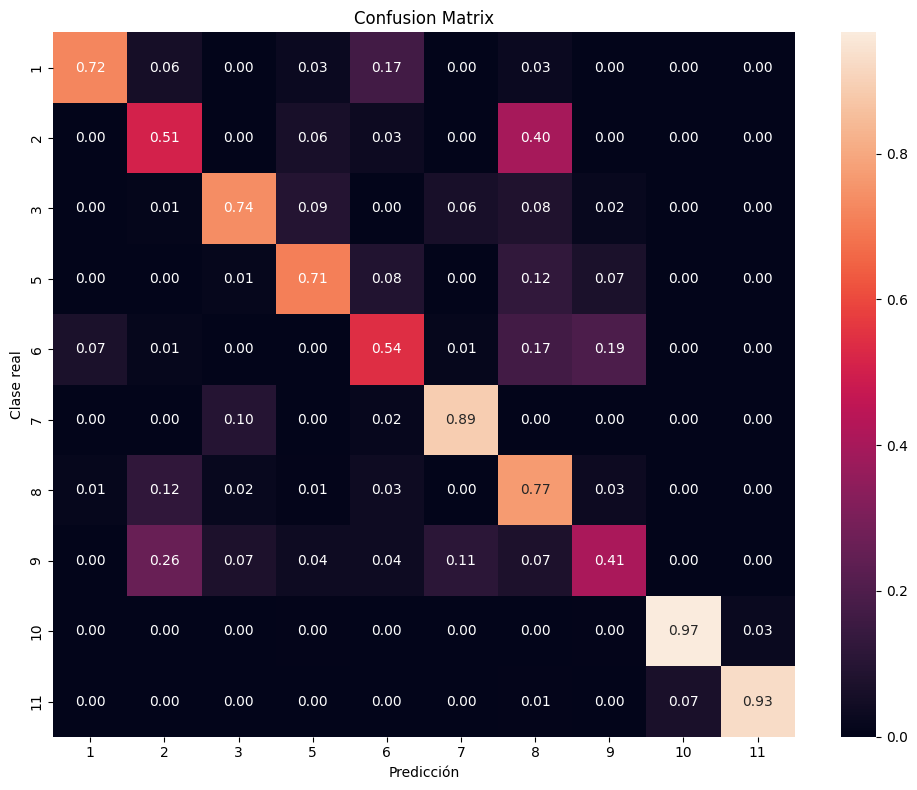

In [11]:
# Matriz normalizada por clase real: cada fila suma 1 si tiene ejemplos.
clases_tope = sorted(set(y_true_tope) | set(y_pred_tope))
matriz_confusion_tope = confusion_matrix(
    y_true_tope,
    y_pred_tope,
    labels=clases_tope,
    normalize="true",
)
figura_matriz_confusion_tope = graficar_matriz_confusion(
    matriz=matriz_confusion_tope,
    nombres_clases=[str(clase) for clase in clases_tope],
)

print(
    "Matriz de confusión normalizada por clase\nPara los fragmentos que se inician desde el Borde Superior"
)

In [12]:
tabla_predicciones_base = seleccionar_predicciones_por_borde_origen(
    tabla_predicciones_valores_a_enteros, borde_origen="base"
)
y_true_base, y_pred_base = obtener_clases_reales_y_predichas(tabla_predicciones_base)

print("Reporte de clasificación.\nFragmentos que se inician desde la base")

print(
    classification_report(
        y_true_base,
        y_pred_base,
    )
)

Reporte de clasificación.
Fragmentos que se inician desde la base
              precision    recall  f1-score   support

           1       0.94      0.94      0.94        36
           2       0.43      0.89      0.58        63
           3       0.69      0.63      0.66        99
           5       0.84      0.99      0.90        72
           6       0.71      0.50      0.59        72
           7       0.77      0.95      0.85        63
           8       0.86      0.72      0.78       378
           9       0.65      0.63      0.64        27
          10       0.77      0.82      0.79       477
          11       0.36      0.28      0.31       162

    accuracy                           0.72      1449
   macro avg       0.70      0.73      0.70      1449
weighted avg       0.73      0.72      0.72      1449



Matriz de confusión normalizada por clase
Para los fragmentos que se inician desde la base


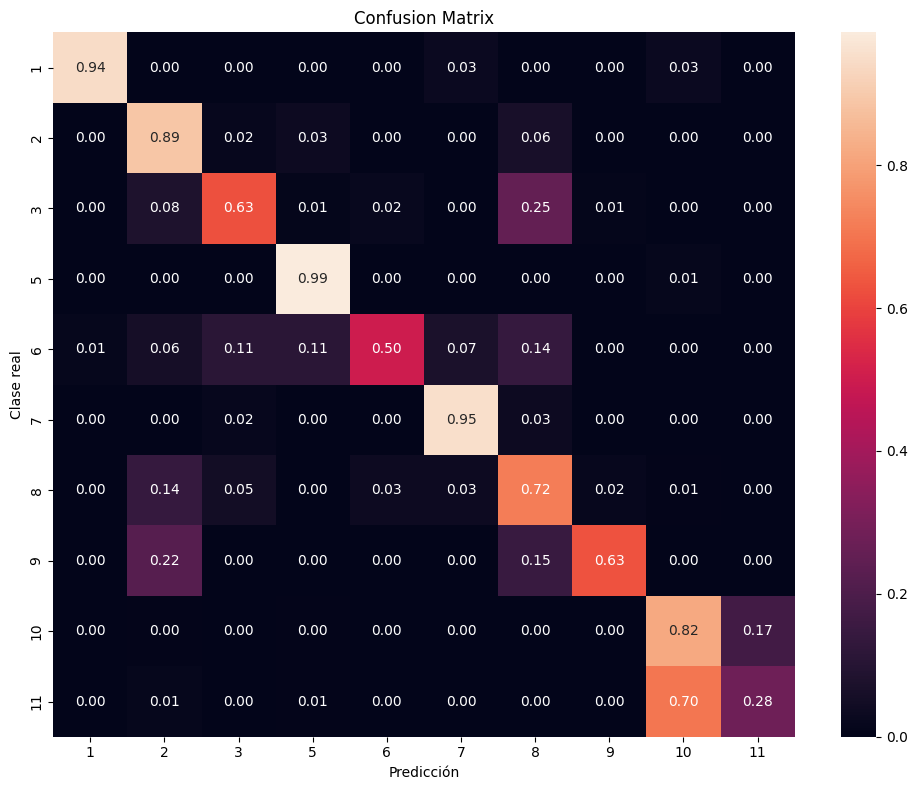

In [13]:
# Matriz normalizada por clase real: cada fila suma 1 si tiene ejemplos.
y_true_base, y_pred_base = obtener_clases_reales_y_predichas(tabla_predicciones_base)
clases_base = sorted(set(y_true_base) | set(y_pred_base))
matriz_confusion_base = confusion_matrix(
    y_true_base,
    y_pred_base,
    labels=clases_base,
    normalize="true",
)
figura_matriz_confusion_base = graficar_matriz_confusion(
    matriz=matriz_confusion_base,
    nombres_clases=[str(clase) for clase in clases_base],
)

print(
    "Matriz de confusión normalizada por clase\nPara los fragmentos que se inician desde la base"
)

In [14]:
print("Tipos de bases existentes en el conjunto de datos:")
tabla_predicciones_valores_a_enteros["Base"].value_counts().sort_index()

Tipos de bases existentes en el conjunto de datos:


Base
1    1862
2    1045
3      76
4      76
Name: count, dtype: int64

## Acierto de Clase Ana según el tipo de base

La exactitud de cada grupo es **100 × predicciones correctas de Clase Ana / imágenes del tipo de base**. El gráfico siguiente muestra este porcentaje de aciertos para cada tipo de base. Se usan todas las imágenes de test, incluidos los perfiles completos y los cortes desde ambos extremos.

Los tamaños de los grupos y la distribución de Clase Ana pueden ser diferentes: esta comparación describe el rendimiento observado por tipo de base. Para desglosarlo por clase, se puede usar un mapa de calor de exactitud con Clase Ana en las filas y Base en las columnas.

La variable `COLUMNA_TIPO` permite cambiar la agrupación a `Borde`. Para restringir el análisis a cortes desde la base, asignar `tabla_predicciones_base` a `tabla_evaluacion_por_tipo`.

In [15]:
COLUMNA_TIPO = "Base"  # Cambiar por "Borde" para comparar los tipos de borde.
tabla_evaluacion_por_tipo = tabla_predicciones_valores_a_enteros
# Para evaluar solo cortes desde la base, usar tabla_predicciones_base.

exactitud_por_tipo = calcular_exactitud_por_grupo(
    tabla_predicciones=tabla_evaluacion_por_tipo,
    columna=COLUMNA_TIPO,
)
exactitud_por_tipo.round({"exactitud_porcentual": 2})

,Base,imagenes,aciertos,errores,exactitud_porcentual
0,1,1862,1373,489,73.74
1,2,1045,871,174,83.35
2,3,76,70,6,92.11
3,4,76,64,12,84.21


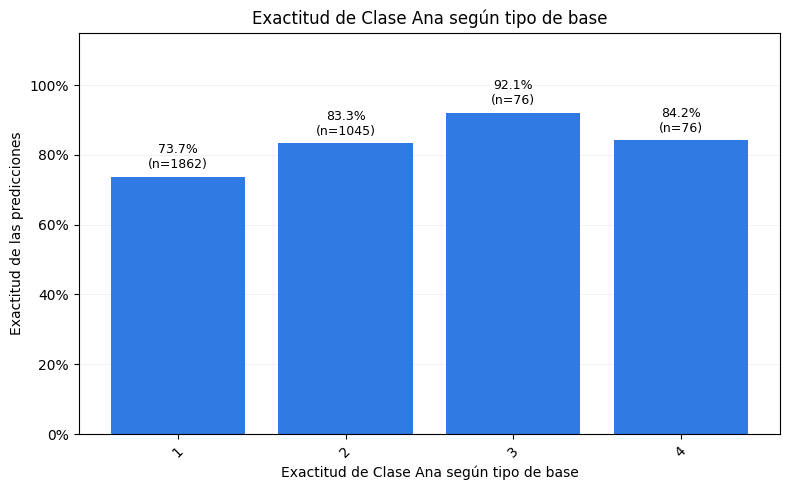

In [16]:
exactitud_por_tipo = graficar_exactitud_por_grupo(
    tabla_predicciones=tabla_evaluacion_por_tipo,
    columna=COLUMNA_TIPO,
    etiqueta=f"Exactitud de Clase Ana según tipo de {COLUMNA_TIPO.lower()}",
    tipo_grafico="barras",
)

In [17]:
tabla_predicciones_valores_a_enteros["Borde"].value_counts().sort_index()

Borde
1     1159
3       19
4      285
7      779
8       57
9       38
11     437
13      38
14      95
15      38
17     114
Name: count, dtype: int64

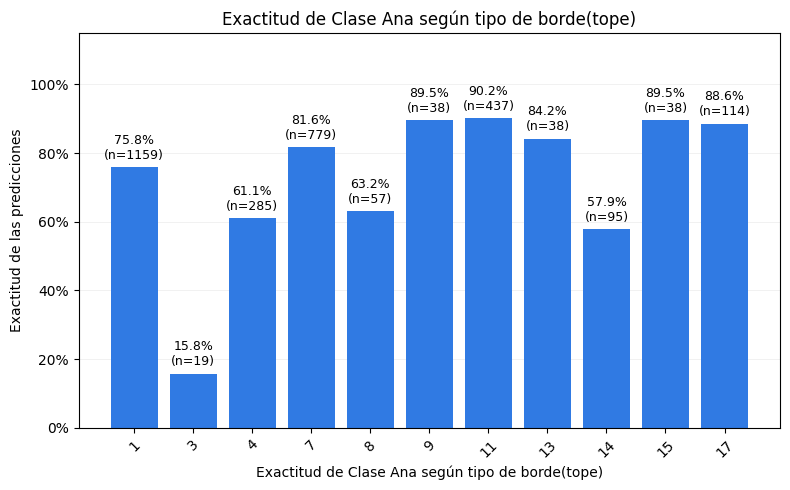

,Borde,imagenes,aciertos,errores,exactitud_porcentual
0,1,1159,879,280,75.841242
1,3,19,3,16,15.789474
2,4,285,174,111,61.052632
3,7,779,636,143,81.643132
4,8,57,36,21,63.157895
5,9,38,34,4,89.473684
6,11,437,394,43,90.160183
7,13,38,32,6,84.210526
8,14,95,55,40,57.894737
9,15,38,34,4,89.473684


In [18]:
graficar_exactitud_por_grupo(
    tabla_predicciones=tabla_predicciones,
    columna="Borde",
    etiqueta="Exactitud de Clase Ana según tipo de borde(tope)",
    tipo_grafico="barras",
)

## Exactitud según avance del corte y borde de origen

El gráfico compara **Tope** y **Base** para cada porcentaje de avance.
Cada punto o barra representa **100 × aciertos / imágenes del grupo (avance, borde de origen)**.
La línea horizontal continua verde indica la exactitud observada en los **perfiles completos**, calculada con sus predicciones reales.

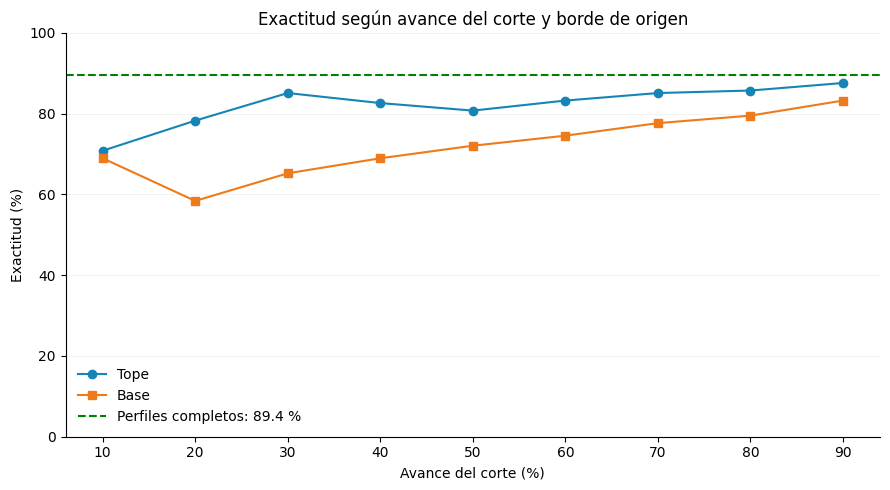

,porcentaje_avance,borde_origen,aciertos,imagenes,exactitud_porcentual
0,10.0,base,111,161,68.944099
1,10.0,tope,114,161,70.807453
2,20.0,base,94,161,58.385093
3,20.0,tope,126,161,78.260870
4,30.0,base,105,161,65.217391
5,30.0,tope,137,161,85.093168
6,40.0,base,111,161,68.944099
7,40.0,tope,133,161,82.608696
8,50.0,base,116,161,72.049689
9,50.0,tope,130,161,80.745342


In [19]:
exactitud_por_avance_y_origen = graficar_metrica_por_avance_y_origen(
    tabla_predicciones,
    metrica="exactitud",
)

exactitud_por_avance_y_origen

## F1 macro según avance del corte y borde de origen

F1 macro es el promedio de F1 de las diez clases de Ana, con el mismo peso para cada clase. Se calcula a partir de las clases reales y predichas de cada grupo (avance, origen), usando las mismas clases en todos los grupos y `zero_division=0`.

El gráfico muestra **100 × F1 macro**, en una escala de 0 a 100. La línea continua verde corresponde al F1 macro calculado sobre todas las predicciones de perfiles completos. La función reutilizable `graficar_metrica_por_avance_y_origen` admite `metrica="exactitud"` o `metrica="f1_macro"`, y gráficos de líneas o barras.

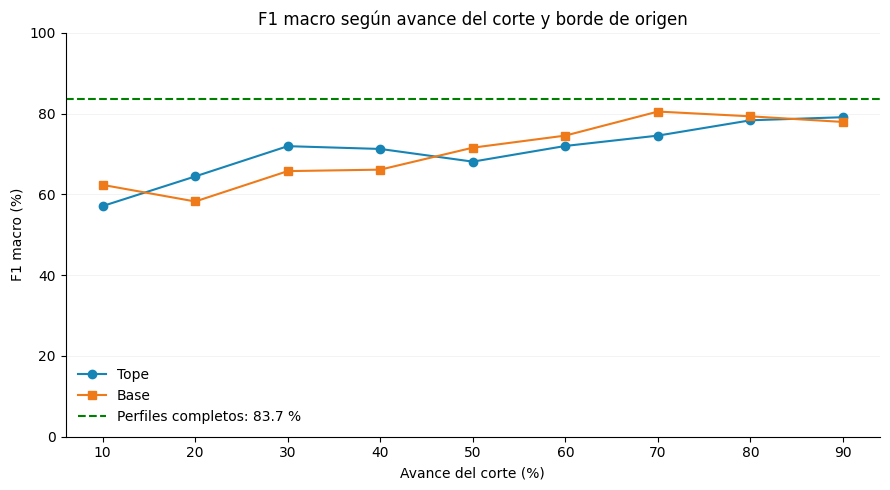

porcentaje_avance,borde_origen,aciertos,imagenes,f1_macro_porcentual
10.000000,base,111,161,62.352443
20.000000,base,94,161,58.242310
30.000000,base,105,161,65.763443
40.000000,base,111,161,66.126919
50.000000,base,116,161,71.567766
60.000000,base,120,161,74.558877
70.000000,base,125,161,80.507889
80.000000,base,128,161,79.327557
90.000000,base,134,161,77.932557
100.000000,completo,144,161,83.697198


In [20]:
f1_macro_por_avance_y_origen = graficar_metrica_por_avance_y_origen(
    tabla_predicciones, metrica="f1_macro"
)

f1_macro_por_avance_y_origen.sort_values(
    ["borde_origen", "porcentaje_avance"]
).style.hide(axis="index")

## Recall por clase y porcentaje conservado

Cada celda muestra **100 × aciertos / ejemplos de la clase y porcentaje seleccionados**, con la misma escala de color de 0 a 100. Se muestran las clases 1–11 excepto la 4. La fila **Media (macro)** promedia el recall de las clases con ejemplos en cada porcentaje; los grupos sin ejemplos se marcan con **—** y no se incluyen en esa media.

Cambiar `BORDE_ORIGEN_MAPA` por `"tope"`, `"base"` o `"completo"`. Para los perfiles completos se muestra una única columna al 100 %. La matriz sin redondear queda en `recall_por_clase_y_avance`.

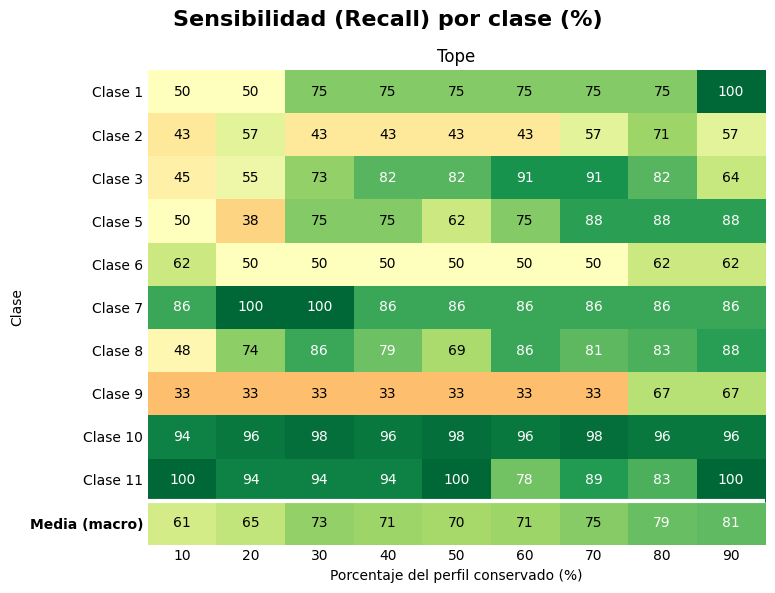

In [21]:
from vasijas.evaluacion import graficar_recall_por_clase_y_avance

BORDE_ORIGEN_MAPA = "tope"  # Opciones: "tope", "base", "completo".
recall_por_clase_y_avance = graficar_recall_por_clase_y_avance(
    tabla_predicciones=tabla_predicciones,
    borde_origen=BORDE_ORIGEN_MAPA,
)

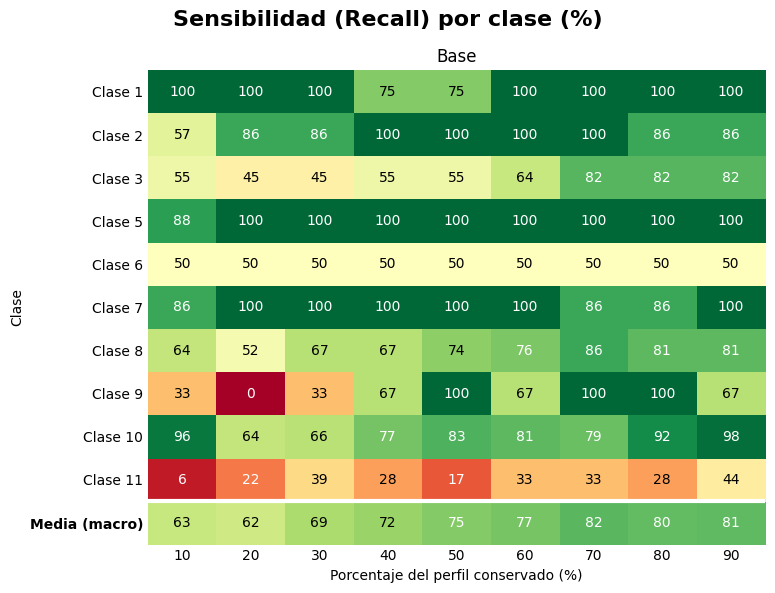

In [22]:
from vasijas.evaluacion import graficar_recall_por_clase_y_avance

BORDE_ORIGEN_MAPA = "base"  # Opciones: "tope", "base", "completo".
recall_por_clase_y_avance = graficar_recall_por_clase_y_avance(
    tabla_predicciones=tabla_predicciones,
    borde_origen=BORDE_ORIGEN_MAPA,
)

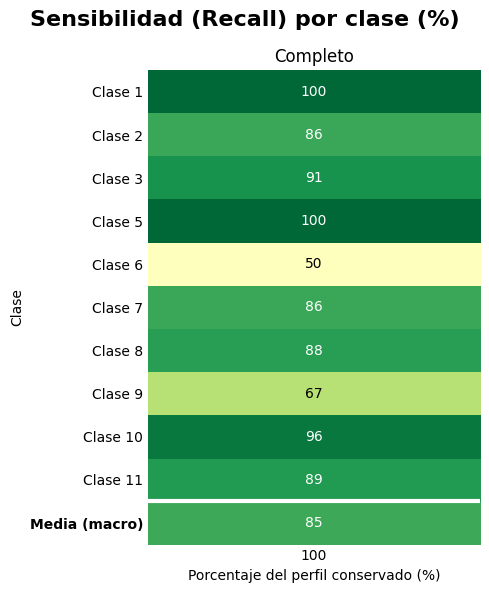

In [23]:
from vasijas.evaluacion import graficar_recall_por_clase_y_avance

BORDE_ORIGEN_MAPA = "completo"  # Opciones: "tope", "base", "completo".
recall_por_clase_y_avance = graficar_recall_por_clase_y_avance(
    tabla_predicciones=tabla_predicciones,
    borde_origen=BORDE_ORIGEN_MAPA,
)